# Electricity demand and temperature in Catalonia

**Question:** how does daily electricity demand in Catalonia change with temperature, and does heat add more demand than cold?

Part of the group project, by Gabriel Albasini. Data are downloaded through open data APIs and cached in `data/raw/` by `xema.py` (the first run needs internet). Figures are saved to `figures/Gabri/`: `energy_demand_vs_temperature` (main), `energy_demand_vs_date` and `energy_demand_by_hour`.

In [1]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.colors import TwoSlopeNorm

import xema  # download and cache helpers (notebook/xema.py)

## 1. Temperature (XEMA)

Daily mean temperature (variable 1000) at Barcelona - el Raval (X4), an urban station, 2019-2025. Check the date range and the missing days.

In [2]:
STATION = "X4"  # Barcelona - el Raval (urban, 33 m); D5 Fabra is in Collserola (410 m)
t = xema.download_daily(STATION, "1000", "2019-01-01", "2025-12-31")
print(t.shape)
print(t["date"].min(), t["date"].max())
print(t["value"].isna().sum())
print(t["date"].diff().value_counts().head())
t.describe()

(2557, 2)
2019-01-01 00:00:00 2025-12-31 00:00:00
0
date
1 days    2556
Name: count, dtype: int64


,date,value
count,2557,2557.000000
mean,2022-07-02 00:00:00,18.551388
min,2019-01-01 00:00:00,6.000000
25%,2020-10-01 00:00:00,13.600000
50%,2022-07-02 00:00:00,17.700000
75%,2024-04-01 00:00:00,23.700000
max,2025-12-31 00:00:00,32.500000
std,NaN,5.758722


In [3]:
full = pd.date_range("2019-01-01", "2025-12-31", freq="D")
missing = full.difference(t["date"])
print(missing)

DatetimeIndex([], dtype='datetime64[us]', freq='D')


## 2. Electricity demand

Daily electricity demand in Catalonia (dataset `hx6q-ykhb`, MWh). Monthly means as a first look.

(2557, 2) 0


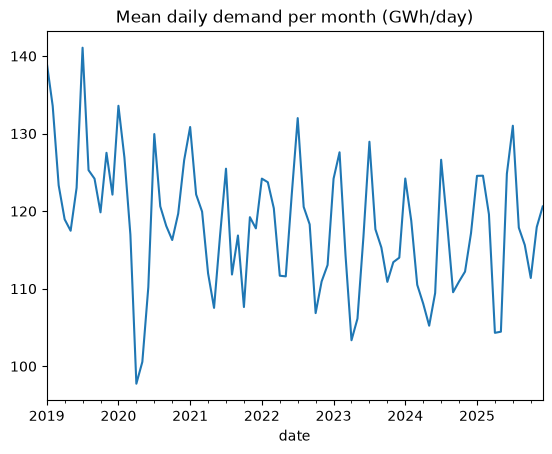

In [4]:
d = xema.download_demand("2019-01-01", "2025-12-31")
print(d.shape, d["demand_mwh"].isna().sum())

monthly = d.set_index("date")["demand_mwh"].resample("MS").mean() / 1000
monthly.plot(title="Mean daily demand per month (GWh/day)");

## 3. Sample: working days 2022-2025

Join demand and temperature by date. Keep weekdays from 2022 on that are not Catalan public holidays, so that weekends and holidays do not hide the temperature effect.

In [5]:
t = xema.download_daily(STATION, "1000", "2019-01-01", "2025-12-31")
t = t.rename(columns={"value": "temp_c"})
d = xema.download_demand("2019-01-01", "2025-12-31")

df = d.merge(t, on="date", how="inner", validate="one_to_one")
df["weekday"] = df["date"].dt.day_of_week
df["is_weekday"] = df["weekday"] < 5
print(df.shape)
print(df["is_weekday"].mean())

(2557, 5)
0.7145091904575674


In [6]:
cat = holidays.Spain(subdiv="CT", years=range(2022, 2026))
for day, name in sorted(cat.items()):
    print(day, name)

2022-01-01 Año Nuevo
2022-01-06 Epifanía del Señor
2022-04-15 Viernes Santo
2022-04-18 Lunes de Pascua
2022-06-06 Día de la Pascua Granada
2022-06-24 San Juan
2022-08-15 Asunción de la Virgen
2022-10-12 Fiesta Nacional de España
2022-11-01 Todos los Santos
2022-12-06 Día de la Constitución Española
2022-12-08 Inmaculada Concepción
2022-12-26 San Esteban
2023-01-06 Epifanía del Señor
2023-04-07 Viernes Santo
2023-04-10 Lunes de Pascua
2023-05-01 Fiesta del Trabajo
2023-06-24 San Juan
2023-08-15 Asunción de la Virgen
2023-09-11 Fiesta Nacional de Cataluña
2023-10-12 Fiesta Nacional de España
2023-11-01 Todos los Santos
2023-12-06 Día de la Constitución Española
2023-12-08 Inmaculada Concepción
2023-12-25 Natividad del Señor
2023-12-26 San Esteban
2024-01-01 Año Nuevo
2024-01-06 Epifanía del Señor
2024-03-29 Viernes Santo
2024-04-01 Lunes de Pascua
2024-05-01 Fiesta del Trabajo
2024-06-24 San Juan
2024-08-15 Asunción de la Virgen
2024-09-11 Fiesta Nacional de Cataluña
2024-10-12 Fiesta Na

In [7]:
df["is_holiday"] = df["date"].dt.date.isin(cat.keys())
sel = df.loc[
    (df["date"] >= "2022-01-01")
    & df["is_weekday"]
    & ~df["is_holiday"]
].copy()
print(sel.shape)

(998, 6)


## 4. Demand against temperature

First look. August stands apart (lower demand at high temperature, the holiday month), so it is left out of the fit.

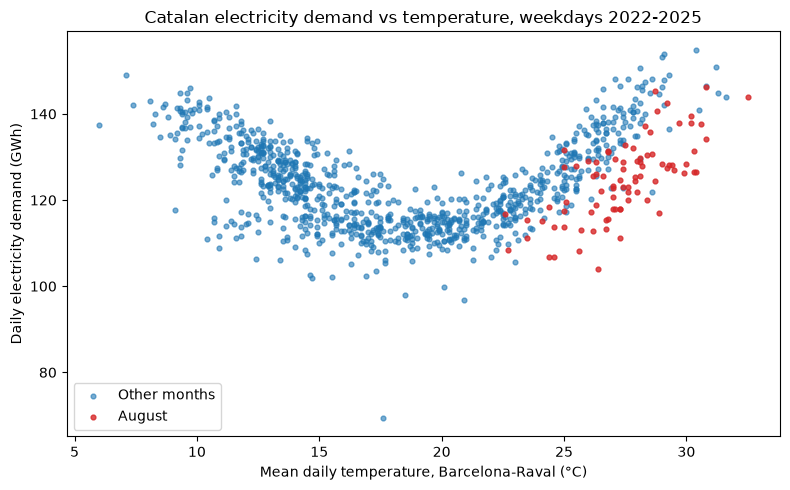

In [8]:
sel = sel.assign(
    demand_gwh=sel["demand_mwh"] / 1000,
    is_august=sel["date"].dt.month == 8,
)

fig, ax = plt.subplots(figsize=(8, 5))
other = sel.loc[~sel["is_august"]]
aug = sel.loc[sel["is_august"]]
ax.scatter(other["temp_c"], other["demand_gwh"], s=12, alpha=0.6, label="Other months")
ax.scatter(aug["temp_c"], aug["demand_gwh"], s=12, alpha=0.8, color="tab:red", label="August")
ax.set_xlabel("Mean daily temperature, Barcelona-Raval (°C)")
ax.set_ylabel("Daily electricity demand (GWh)")
ax.set_title("Catalan electricity demand vs temperature, weekdays 2022-2025")
ax.legend()
fig.tight_layout()

## 5. Piecewise linear fit

Model: demand = base + a·max(0, T_cold − T) + b·max(0, T − T_hot). The two thresholds are found by a grid search in steps of 0.5 °C; the three coefficients by least squares. August and 28 April 2025 (Iberian blackout) are excluded, which leaves 912 days.

In [9]:
fit = sel.loc[~sel["is_august"] & (sel["date"] != "2025-04-28")]
t = fit["temp_c"].to_numpy()
y = fit["demand_gwh"].to_numpy()


def hinge_fit(t, y, t_cold, t_hot):
    X = np.column_stack([
        np.ones(len(t)),
        np.clip(t_cold - t, 0, None),
        np.clip(t - t_hot, 0, None),
    ])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    rss = ((y - X @ coef) ** 2).sum()
    return coef, rss


best = None
for t_cold in np.arange(10, 20.5, 0.5):
    for t_hot in np.arange(t_cold, 24.5, 0.5):
        coef, rss = hinge_fit(t, y, t_cold, t_hot)
        if best is None or rss < best[0]:
            best = (rss, t_cold, t_hot, coef)

print(len(fit), best[1], best[2], best[3])

912 17.0 22.0 [114.37699779   2.91061843   4.22932855]


Main figure: demand as % above the fitted base load (a mild day), coloured by season.

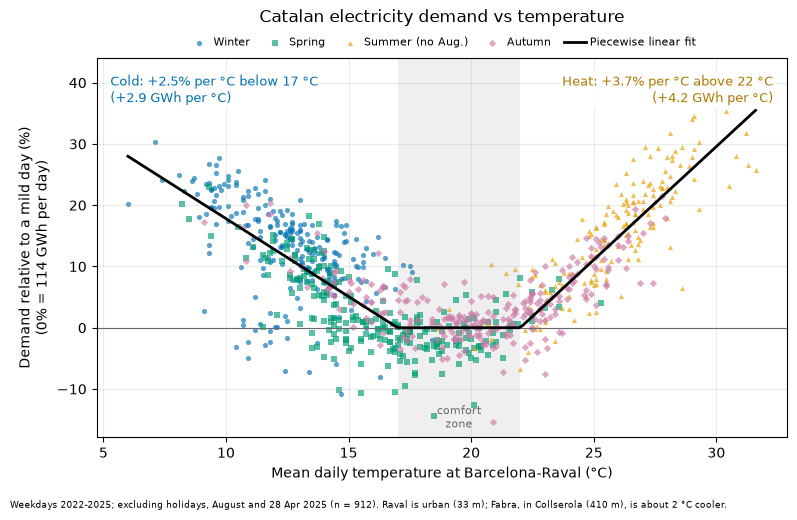

In [10]:
base, s_cold, s_hot = best[3]
t_cold, t_hot = best[1], best[2]

# Relative scale: % above (or below) the demand of a mild day, i.e. the fitted base load
fit = fit.assign(
    season=fit["date"].dt.month % 12 // 3,  # 0 Dec-Feb, 1 Mar-May, 2 Jun-Aug, 3 Sep-Nov
    rel_pct=100 * (fit["demand_gwh"] / base - 1),
)
rel_cold, rel_hot = 100 * s_cold / base, 100 * s_hot / base  # slopes in % per °C

# Okabe-Ito colours (safe for the common colour-vision deficiencies) plus a marker per season
SEASONS = {0: ("Winter", "#0072B2", "o"), 1: ("Spring", "#009E73", "s"),
           2: ("Summer (no Aug.)", "#E69F00", "^"), 3: ("Autumn", "#CC79A7", "D")}

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.axvspan(t_cold, t_hot, color="grey", alpha=0.12, lw=0)
ax.axhline(0, color="dimgrey", lw=0.8)
for k, (name, color, marker) in SEASONS.items():
    d = fit.loc[fit["season"] == k]
    ax.scatter(d["temp_c"], d["rel_pct"], s=14, alpha=0.65, color=color, marker=marker,
               lw=0, label=name)

grid = np.linspace(fit["temp_c"].min(), fit["temp_c"].max(), 200)
curve = 100 * (s_cold * np.clip(t_cold - grid, 0, None)
               + s_hot * np.clip(grid - t_hot, 0, None)) / base
ax.plot(grid, curve, color="black", lw=2, label="Piecewise linear fit")

box = dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2)
ax.text(0.02, 0.96, f"Cold: +{rel_cold:.1f}% per °C below {t_cold:.0f} °C\n"
        f"(+{s_cold:.1f} GWh per °C)", transform=ax.transAxes, ha="left", va="top",
        fontsize=9, bbox=box, color=SEASONS[0][1])
ax.text(0.98, 0.96, f"Heat: +{rel_hot:.1f}% per °C above {t_hot:.0f} °C\n"
        f"(+{s_hot:.1f} GWh per °C)", transform=ax.transAxes, ha="right", va="top",
        fontsize=9, bbox=box, color="#B07800")
ax.text((t_cold + t_hot) / 2, ax.get_ylim()[0] + 1, "comfort\nzone", fontsize=8,
        ha="center", va="bottom", color="dimgrey")

ax.set_ylim(top=44)  # room for the slope labels above the points
ax.grid(alpha=0.25)
ax.set_xlabel("Mean daily temperature at Barcelona-Raval (°C)")
ax.set_ylabel(f"Demand relative to a mild day (%)\n(0% = {base:.0f} GWh per day)")
ax.set_title("Catalan electricity demand vs temperature", pad=26)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, fontsize=8,
          frameon=False, columnspacing=1.2, handletextpad=0.3)
fig.text(0.01, 0.012,
         "Weekdays 2022-2025; excluding holidays, August and 28 Apr 2025 (n = 912). "
         "Raval is urban (33 m); Fabra, in Collserola (410 m), is about 2 °C cooler.",
         fontsize=6.5, ha="left")
fig.tight_layout(rect=(0, 0.035, 1, 1))

out = Path("..") / "figures" / "Gabri"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "energy_demand_vs_temperature.png", dpi=200)


## 6. Temperature or calendar?

Does the date alone (a smooth seasonal curve with two annual harmonics) explain demand as well as temperature? Both models are compared by R² on the same 912 days (in sample).

In [11]:
# Same 912 days against the calendar: does the date explain demand as well as temperature?


def r2(y, yhat):
    """Share of the variance of y explained by the prediction yhat."""
    return 1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum()


y_rel = fit["rel_pct"].to_numpy()
doy = fit["date"].dt.day_of_year.to_numpy()
w = 2 * np.pi * doy / 365.25
# calendar model: a smooth seasonal curve (mean + two annual harmonics), least squares
X_cal = np.column_stack([np.ones(len(w)), np.cos(w), np.sin(w), np.cos(2 * w), np.sin(2 * w)])
coef_cal, *_ = np.linalg.lstsq(X_cal, y_rel, rcond=None)
# temperature model: the piecewise linear fit above, on the same relative scale
temp = fit["temp_c"].to_numpy()
pred_temp = 100 * (s_cold * np.clip(t_cold - temp, 0, None)
                   + s_hot * np.clip(temp - t_hot, 0, None)) / base

r2_cal, r2_temp = r2(y_rel, X_cal @ coef_cal), r2(y_rel, pred_temp)
print(f"R2 calendar = {r2_cal:.2f}   R2 temperature = {r2_temp:.2f}   (n = {len(y_rel)})")


R2 calendar = 0.52   R2 temperature = 0.67   (n = 912)


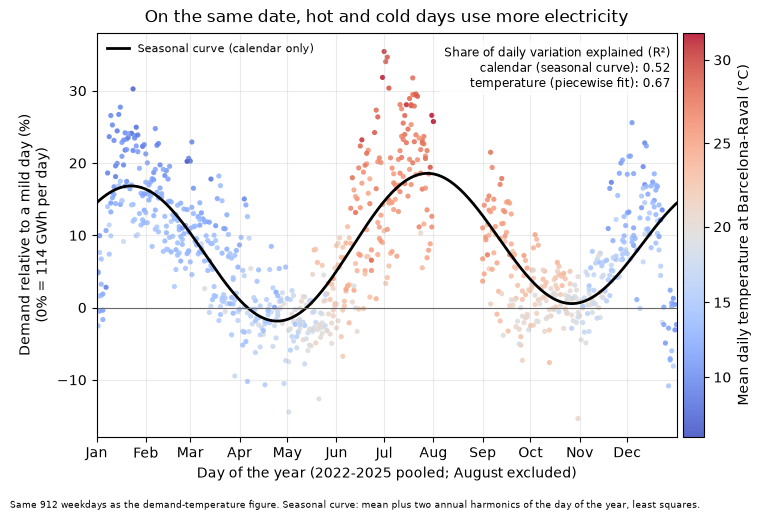

In [12]:
fig, ax = plt.subplots(figsize=(8, 5.2))
# diverging map centred on the comfort zone: blue = cold day, red = hot day (CVD-friendly)
norm = TwoSlopeNorm(vmin=temp.min(), vcenter=(t_cold + t_hot) / 2, vmax=temp.max())
sc = ax.scatter(doy, y_rel, c=temp, cmap="coolwarm", norm=norm, s=14, alpha=0.85, lw=0)
cb = fig.colorbar(sc, ax=ax, pad=0.01)
cb.set_label("Mean daily temperature at Barcelona-Raval (°C)")

g = np.arange(1, 367)
wg = 2 * np.pi * g / 365.25
cal_curve = np.column_stack([np.ones(len(g)), np.cos(wg), np.sin(wg),
                             np.cos(2 * wg), np.sin(2 * wg)]) @ coef_cal
ax.plot(g, cal_curve, color="black", lw=2, label="Seasonal curve (calendar only)")
ax.axhline(0, color="dimgrey", lw=0.8)

starts = pd.date_range("2023-01-01", periods=12, freq="MS")
ax.set_xticks(starts.day_of_year, starts.strftime("%b"))
ax.set_xlim(1, 366)
ax.set_xlabel("Day of the year (2022-2025 pooled; August excluded)")
ax.set_ylabel(f"Demand relative to a mild day (%)\n(0% = {base:.0f} GWh per day)")
ax.set_title("On the same date, hot and cold days use more electricity", pad=8)
ax.legend(loc="upper left", fontsize=8, frameon=False)
box = dict(facecolor="white", alpha=0.85, edgecolor="none", pad=3)
ax.text(0.99, 0.97, f"Share of daily variation explained (R²)\n"
        f"calendar (seasonal curve): {r2_cal:.2f}\n"
        f"temperature (piecewise fit): {r2_temp:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=8.5, bbox=box)
ax.grid(alpha=0.25)
fig.text(0.01, 0.012,
         "Same 912 weekdays as the demand-temperature figure. Seasonal curve: mean plus two "
         "annual harmonics of the day of the year, least squares.", fontsize=6.5, ha="left")
fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.savefig(out / "energy_demand_vs_date.png", dpi=200)


## 7. Hour of the day

Same days, hourly columns of the same dataset. Clock-change days are dropped, and the 24 hours are checked against the daily total.

In [13]:
# Demand by hour of the day and temperature (same dataset, hourly columns h01-h24)
dh = xema.download_demand_hourly("2022-01-01", "2025-12-31")
hours = [f"h{i:02d}" for i in range(1, 25)]
# drop the two clock-change days per year: h25 > 0 (October) or an empty hour (March)
clock = (dh["h25"] > 0) | (dh[hours] == 0).any(axis=1)
hd = (dh.loc[~clock & dh["date"].isin(fit["date"]), ["date"] + hours]
        .merge(fit[["date", "temp_c"]], on="date", validate="one_to_one"))
print(hd.shape, "clock-change days dropped:", int(clock.sum()))
# check: the 24 hours add up to the daily total used before
chk = hd.set_index("date")[hours].sum(axis=1) / 1000 - fit.set_index("date")["demand_gwh"]
print("max |hourly sum - daily total| (GWh):", round(chk.abs().max(), 3))

# profile: mean demand at each hour (MWh in one hour = average GW x 1000)
prof = hd[hours].to_numpy() / 1000  # GWh per hour = average GW in that hour
mild = (hd["temp_c"] >= t_cold) & (hd["temp_c"] <= t_hot)
ref = prof[mild.to_numpy()].mean(axis=0)  # mild-day profile, the reference at each hour

# heatmap: temperature bins of 2 °C x hour, % above mild days at the same hour
bins = np.arange(4, 34, 2)
hd = hd.assign(tbin=pd.cut(hd["temp_c"], bins, right=False))
rel_h = (hd.groupby("tbin", observed=True)[hours].mean() / 1000 / ref - 1) * 100
n_bin = hd.groupby("tbin", observed=True).size()
rel_h = rel_h.loc[n_bin >= 5]  # hide bins with fewer than 5 days
print(n_bin.to_string())
# extra demand (%) by hour for the coldest and the two hottest bins shown (columns h01-h24 = hours 0-23)
print(rel_h.round(0).astype(int).iloc[[0, -2, -1]].to_string())

(912, 26) clock-change days dropped: 8
max |hourly sum - daily total| (GWh): 0.0
tbin
[6, 8)        3
[8, 10)      34
[10, 12)     72
[12, 14)    137
[14, 16)    135
[16, 18)    100
[18, 20)     83
[20, 22)     86
[22, 24)     87
[24, 26)     76
[26, 28)     70
[28, 30)     23
[30, 32)      6
          h01  h02  h03  h04  h05  h06  h07  h08  h09  h10  h11  h12  h13  h14  h15  h16  h17  h18  h19  h20  h21  h22  h23  h24
tbin                                                                                                                            
[8, 10)    15   13   13   12   13   14   16   21   24   26   26   25   23   22   22   22   22   24   26   26   24   22   21   19
[28, 30)   27   25   24   23   21   19   15   12   15   20   24   27   30   31   33   34   34   33   30   26   21   23   27   28
[30, 32)   30   28   26   24   22   20   15   13   16   22   28   32   35   36   38   39   40   38   35   30   25   27   32   32


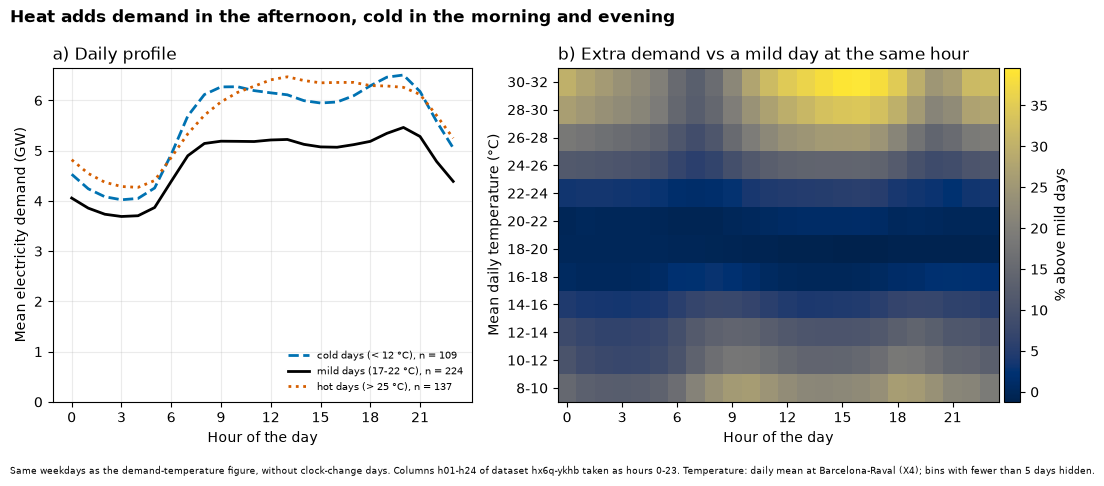

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), width_ratios=[1, 1.25])

groups = {f"cold days (< {t_cold - 5:.0f} °C)": (hd["temp_c"] < t_cold - 5, "#0072B2", "--"),
          f"mild days ({t_cold:.0f}-{t_hot:.0f} °C)": (mild, "black", "-"),
          f"hot days (> {t_hot + 3:.0f} °C)": (hd["temp_c"] > t_hot + 3, "#D55E00", ":")}
for label, (mask, color, ls) in groups.items():
    m = mask.to_numpy()
    ax1.plot(range(24), prof[m].mean(axis=0), color=color, ls=ls, lw=2,
             label=f"{label}, n = {m.sum()}")
ax1.set_xticks(range(0, 24, 3))
ax1.set_xlabel("Hour of the day")
ax1.set_ylabel("Mean electricity demand (GW)")
ax1.set_ylim(bottom=0)  # axis from zero, so the gaps between curves are not exaggerated
ax1.set_title("a) Daily profile", loc="left")
ax1.legend(fontsize=7.5, frameon=False, loc="lower right")
ax1.grid(alpha=0.25)

vmax = np.nanmax(np.abs(rel_h.to_numpy()))
im = ax2.imshow(rel_h.to_numpy(), aspect="auto", origin="lower", cmap="cividis",
                vmin=min(0, np.nanmin(rel_h.to_numpy())), vmax=vmax,
                extent=(-0.5, 23.5, -0.5, len(rel_h) - 0.5))
ax2.set_yticks(range(len(rel_h)), [f"{iv.left:.0f}-{iv.right:.0f}" for iv in rel_h.index])
ax2.set_xticks(range(0, 24, 3))
ax2.set_xlabel("Hour of the day")
ax2.set_ylabel("Mean daily temperature (°C)")
ax2.set_title("b) Extra demand vs a mild day at the same hour", loc="left")
cb = fig.colorbar(im, ax=ax2, pad=0.01)
cb.set_label("% above mild days")
ax2.grid(False)

fig.suptitle("Heat adds demand in the afternoon, cold in the morning and evening",
             fontweight="bold", x=0.01, ha="left")
fig.text(0.01, 0.012,
         "Same weekdays as the demand-temperature figure, without clock-change days. Columns "
         "h01-h24 of dataset hx6q-ykhb taken as hours 0-23. Temperature: daily mean at "
         "Barcelona-Raval (X4); bins with fewer than 5 days hidden.", fontsize=6.5, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(out / "energy_demand_by_hour.png", dpi=200)


## 8. Choice of weather station

The same fit with three Barcelona stations, to see how much thresholds and slopes depend on the station.

In [15]:
# Same fit, same 912 days, with three Barcelona stations
# (station metadata comes from the XEMA stations dataset yqwd-vj5e)

meta = pd.DataFrame(requests.get(
    "https://analisi.transparenciacatalunya.cat/resource/yqwd-vj5e.json",
    params={"$where": "codi_estacio in('D5','X4','X8')"}, timeout=30,
).json()).set_index("codi_estacio")
meta = meta.assign(altitude_m=pd.to_numeric(meta["altitud"]))
area = {
    "X4": "Ciutat Vella: dense old town, urban",
    "X8": "Les Corts: UB campus, mid-city",
    "D5": "Collserola hills: forest, above the city",
}

dem = xema.download_demand("2019-01-01", "2025-12-31")
rows = []
for st in ["X4", "X8", "D5"]:
    ts = xema.download_daily(st, "1000", "2019-01-01", "2025-12-31")
    ts = ts.rename(columns={"value": "temp_c"})
    s = dem.merge(ts, on="date").loc[lambda x: x["date"].isin(fit["date"])]
    t = s["temp_c"].to_numpy()
    y = s["demand_mwh"].to_numpy() / 1000
    best_st = None
    for tc in np.arange(10, 20.5, 0.5):
        for th in np.arange(tc, 24.5, 0.5):
            coef, rss = hinge_fit(t, y, tc, th)
            if best_st is None or rss < best_st[0]:
                best_st = (rss, tc, th, coef)
    rows.append({
        "station": st, "n": len(s), "t_cold": best_st[1], "t_hot": best_st[2],
        "slope_cold": round(best_st[3][1], 2), "slope_hot": round(best_st[3][2], 2),
        "rmse_gwh": round((best_st[0] / len(s)) ** 0.5, 2),
    })

res = pd.DataFrame(rows).set_index("station")
info = meta.loc[res.index, ["nom_estacio", "emplacament", "altitude_m", "latitud", "longitud"]]
info.insert(1, "area", pd.Series(area))
pd.concat([info, res], axis=1)


,nom_estacio,area,emplacament,altitude_m,latitud,longitud,n,t_cold,t_hot,slope_cold,slope_hot,rmse_gwh
X4,Barcelona - el Raval,"Ciutat Vella: dense old town, urban",Facultat de Geografia i Història. c. Montalegr...,33,41.38386,2.16774,912,17.0,22.0,2.91,4.23,5.80
X8,Barcelona - Zona Universitària,"Les Corts: UB campus, mid-city",Pistes UB,82,41.37922,2.10537,912,17.0,21.0,2.54,3.90,5.76
D5,Barcelona - Observatori Fabra,"Collserola hills: forest, above the city",Observatori Fabra,410,41.41864,2.12379,912,15.0,19.0,2.42,3.22,6.20


## Summary and limits

- Comfort zone between 17 and 22 °C, with a base load of about 114 GWh per day.
- Demand rises about 2.9 GWh (2.5%) per °C below 17 °C and 4.2 GWh (3.7%) per °C above 22 °C: heat weighs more than cold.
- Temperature explains R² = 0.67 of the daily variation, the calendar alone 0.52.
- Limits: one station for all of Catalonia, four years of data, in-sample fit, no correction for prices or economic activity.